### DP1 VISTA correlated-noise calibration — RSP
This analysis estimates band-dependent corrections to circular-aperture flux uncertainties using blank-sky measurements on the DP1 VISTA coadds. It uses the coadd and forced-photometry RUN collections in the `lsst-ir-fusion-dp1` Butler repository.
The calibration covers **Z, Y, J, H and K** and the seven catalogue aperture radii **3, 4.5, 6, 9, 12, 17 and 25 pixels**. Larger apertures are tested only to document the sampling limitations; They are not calibrated. Results are checkpointed after **each patch**, allowing interrupted bands to resume. The final output is a set of CSV/JSON calibration products to transfer to CSD3, where catalogue uncertainties will be updated separately.

### 1. Configuration and output location
Both Butler RUN collections are specified explicitly to prevent mixing calibration measurements with products from other processing runs. Small text files are saved in the persistent RSP user workspace, rather than within the Butler repository. After a kernel restart, the setup and definition cells can be rerun; completed patch results remain on disk.

In [1]:
from pathlib import Path
import gc
import json
import warnings
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import distance_transform_edt
from lsst.daf.butler import Butler

REPO = "lsst-ir-fusion-dp1"
COADD_RUN = "u/ir-sare1/DRP/videoCoaddDetect/20260912T090129Z"
FORCED_RUN = "u/ir-sare1/DRP/videoMultiVisits/20260914T000055Z"
SKYMAP = "lsst_cells_v1"
BANDS = ("Z", "Y", "J", "H", "K")
RADII = (3.0, 4.5, 6.0, 9.0, 12.0, 17.0, 25.0)
TARGETS = {3.0: 2000, 4.5: 2000, 6.0: 2000,
           9.0: 1500, 12.0: 1200, 17.0: 700, 25.0: 250}
MIN_APERTURES = {r: (100 if r == 25.0 else 200) for r in RADII}
SEED = 20261022
SAFETY_MARGIN = 2.0  # pixels beyond the aperture radius
OVERSAMPLE = 20      # fractional-circle subpixels along each axis
EXCLUDE_REQUESTED = (
    "BAD", "CLIPPED", "CR", "DETECTED", "DETECTED_NEGATIVE",
    "EDGE", "INTRP", "NO_DATA", "REJECTED", "SAT", "STREAK",
    "SUSPECT", "VIGNETTED", "UNMASKEDNAN", "NOT_DEBLENDED",
    "SENSOR_EDGE",
)
OUTDIR = Path("data/DP1_correlated_noise_RSP")

print("Butler repository:", REPO)
print("Coadd RUN:       ", COADD_RUN)
print("Forced RUN:      ", FORCED_RUN)
print("Sky map:         ", SKYMAP)
print("Output directory:", OUTDIR)
print("Bands:", BANDS, "| Radii (pixels):", RADII)

Butler repository: lsst-ir-fusion-dp1
Coadd RUN:        u/ir-sare1/DRP/videoCoaddDetect/20260912T090129Z
Forced RUN:       u/ir-sare1/DRP/videoMultiVisits/20260914T000055Z
Sky map:          lsst_cells_v1
Output directory: data/DP1_correlated_noise_RSP
Bands: ('Z', 'Y', 'J', 'H', 'K') | Radii (pixels): (3.0, 4.5, 6.0, 9.0, 12.0, 17.0, 25.0)


### 2. Connect to the Butler and verify dataset types
The expected coadd images and forced-source catalogues are checked in the registry. The calibration reads `deepCoadd_calexp` only from the coadd RUN; the forced catalogues are used for checking field names and selecting patches that can ultimately receive corrections. This notebook does not register or write any Butler datasets.

In [2]:
butler = Butler(REPO)
for run in (COADD_RUN, FORCED_RUN):
    print(run, "->", butler.registry.getCollectionType(run))
for dataset_type in ("deepCoadd_calexp", "deepCoadd_forced_src"):
    dt = butler.registry.getDatasetType(dataset_type)
    print(dataset_type, "| dimensions:", dt.dimensions.names,
          "| storage class:", dt.storageClass_name)

u/ir-sare1/DRP/videoCoaddDetect/20260912T090129Z -> 1
u/ir-sare1/DRP/videoMultiVisits/20260914T000055Z -> 1
deepCoadd_calexp | dimensions: {band, skymap, tract, patch} | storage class: ExposureF
deepCoadd_forced_src | dimensions: {band, skymap, tract, patch} | storage class: SourceCatalog


### 3. Match coadds and forced catalogues by band and patch
Only tract–patch–band combinations present in **both** named RUN collections are analysed. The dataset references are retained so each coadd can be retrieved unambiguously and so missing coverage is visible before measuring noise.

In [3]:
coadd_refs = {}
forced_refs = {}
common_by_band = {}
inventory_rows = []

for band in BANDS:
    where = f"skymap='{SKYMAP}' AND band='{band}'"
    coadds = list(butler.registry.queryDatasets(
        "deepCoadd_calexp", collections=[COADD_RUN], where=where
    ))
    catalogues = list(butler.registry.queryDatasets(
        "deepCoadd_forced_src", collections=[FORCED_RUN], where=where
    ))
    coadd_map = {(int(r.dataId["tract"]), int(r.dataId["patch"])): r
                 for r in coadds}
    forced_map = {(int(r.dataId["tract"]), int(r.dataId["patch"])): r
                  for r in catalogues}
    assert len(coadd_map) == len(coadds), f"Duplicate coadds in {band}"
    assert len(forced_map) == len(catalogues), f"Duplicate catalogues in {band}"
    coadd_refs[band] = coadd_map
    forced_refs[band] = forced_map
    common_by_band[band] = sorted(coadd_map.keys() & forced_map.keys())
    inventory_rows.append({
        "band": band, "coadds": len(coadds),
        "forced_catalogues": len(catalogues),
        "common_patches": len(common_by_band[band]),
        "tracts": len({t for t, p in common_by_band[band]}),
    })

inventory = pd.DataFrame(inventory_rows)
print(inventory.to_string(index=False))
if (inventory["common_patches"] == 0).any():
    raise RuntimeError("At least one band has no matching coadd and forced catalogue.")

# Prefer an identifiable reference patch; otherwise select a reproducible alternative.
REFERENCE_PATCH = ((5063, 22) if (5063, 22) in common_by_band["K"]
                   else common_by_band["K"][len(common_by_band["K"]) // 2])
print("\nK-band reference (tract, patch):", REFERENCE_PATCH)

band  coadds  forced_catalogues  common_patches  tracts
   Z      42                 42              42       4
   Y      91                 89              89       5
   J      91                 91              91       5
   H      91                 91              91       5
   K      91                 91              91       5

K-band reference (tract, patch): (5063, 22)


### 4. Inspect the reference coadd and source mask
Image coverage, variance and mask planes are inspected in a K-band reference patch. A source-detection mask is essential: empty apertures contaminated by detected sources would overestimate the background scatter. Only mask planes that exist in the exposure are used; missing optional planes are reported.

In [4]:
reference_ref = coadd_refs["K"][REFERENCE_PATCH]
reference_exp = butler.get(reference_ref)
plane_names = set(reference_exp.mask.getMaskPlaneDict())
for required in ("DETECTED", "NO_DATA"):
    if required not in plane_names:
        raise RuntimeError(f"Required reference mask plane missing: {required}")

print("Dataset RUN:", reference_ref.run)
print("Image shape (y, x):", reference_exp.image.array.shape)
print("Pixel scale (arcsec):",
      reference_exp.getWcs().getPixelScale().asArcseconds())
print("Mask planes:", sorted(plane_names))
print("Excluded planes present:", sorted(plane_names & set(EXCLUDE_REQUESTED)))
print("Excluded planes absent: ", sorted(set(EXCLUDE_REQUESTED) - plane_names))
print("Finite image fraction:",
      round(float(np.mean(np.isfinite(reference_exp.image.array))), 4))
print("Finite positive variance fraction:", round(float(np.mean(
      np.isfinite(reference_exp.variance.array) &
      (reference_exp.variance.array > 0))), 4))

Dataset RUN: u/ir-sare1/DRP/videoCoaddDetect/20260912T090129Z
Image shape (y, x): (3400, 3400)
Pixel scale (arcsec): 0.1999999999598387
Mask planes: ['BAD', 'CLIPPED', 'CR', 'DETECTED', 'DETECTED_NEGATIVE', 'EDGE', 'INEXACT_PSF', 'INTRP', 'NOT_DEBLENDED', 'NO_DATA', 'REJECTED', 'SAT', 'SENSOR_EDGE', 'STREAK', 'SUSPECT', 'UNMASKEDNAN', 'VIGNETTED']
Excluded planes present: ['BAD', 'CLIPPED', 'CR', 'DETECTED', 'DETECTED_NEGATIVE', 'EDGE', 'INTRP', 'NOT_DEBLENDED', 'NO_DATA', 'REJECTED', 'SAT', 'SENSOR_EDGE', 'STREAK', 'SUSPECT', 'UNMASKEDNAN', 'VIGNETTED']
Excluded planes absent:  []
Finite image fraction: 1.0
Finite positive variance fraction: 0.9971


### 5. Reusable blank-aperture measurement functions
Blank-sky positions are selected on a randomly offset grid with centre spacing at least twice the aperture radius plus a 2-pixel margin. This avoids overlap within each radius. Each aperture must lie entirely on unmasked, finite, positive-variance pixels. Fractional circular weights are used, and the noise factor is defined as the NMAD of blank-aperture fluxes centred by their median and divided by their formal variance-plane errors. Zero-weight pixels are excluded explicitly to avoid propagating `NaN × 0` from masked image corners.

In [5]:
def nmad(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 2:
        return np.nan
    med = np.median(x)
    return float(1.4826 * np.median(np.abs(x - med)))


def fractional_circle(radius, oversample=OVERSAMPLE):
    half = int(np.ceil(radius))
    yy, xx = np.mgrid[-half:half + 1, -half:half + 1]
    sub = (np.arange(oversample) + 0.5) / oversample - 0.5
    weights = np.zeros(xx.shape, dtype=float)
    for sy in sub:
        for sx in sub:
            weights += ((xx + sx)**2 + (yy + sy)**2 <= radius**2)
    return weights / oversample**2


WEIGHTS = {r: fractional_circle(r) for r in RADII}


def valid_sky_and_distance(exposure, additional_excluded=()):
    planes = set(exposure.mask.getMaskPlaneDict())
    if not {"DETECTED", "NO_DATA"}.issubset(planes):
        raise RuntimeError("Exposure is missing DETECTED or NO_DATA mask planes")
    excluded = sorted(planes & (set(EXCLUDE_REQUESTED) | set(additional_excluded)))
    bits = exposure.mask.getPlaneBitMask(excluded)
    img = exposure.image.array
    var = exposure.variance.array
    good = (np.isfinite(img) & np.isfinite(var) & (var > 0)
            & ((exposure.mask.array & bits) == 0))
    return good, distance_transform_edt(good)


def candidate_positions(distance, radius, seed):
    ny, nx = distance.shape
    margin = int(np.ceil(radius + SAFETY_MARGIN))
    step = int(np.ceil(2 * (radius + SAFETY_MARGIN)))
    if nx <= 2 * margin + step or ny <= 2 * margin + step:
        return np.empty((0, 2), dtype=np.int32)
    rng = np.random.default_rng(seed)
    xs = np.arange(margin + rng.integers(0, step), nx - margin, step)
    ys = np.arange(margin + rng.integers(0, step), ny - margin, step)
    xx, yy = np.meshgrid(xs, ys)
    keep = distance[yy, xx] > radius + SAFETY_MARGIN
    return np.column_stack((xx[keep], yy[keep])).astype(np.int32)


def sample_positions(distance, radius, target, seed):
    candidates = candidate_positions(distance, radius, seed)
    if len(candidates) <= target:
        return candidates, len(candidates)
    rng = np.random.default_rng(seed + 1)
    selected = rng.choice(len(candidates), size=target, replace=False)
    return candidates[selected], len(candidates)


def aperture_arrays(exposure, positions, radius, weights=None):
    w = WEIGHTS[radius] if weights is None else weights
    half = w.shape[0] // 2
    inside = w > 0
    wi = w[inside]
    w2 = wi**2
    img, var = exposure.image.array, exposure.variance.array
    f = np.empty(len(positions), dtype=float)
    e = np.empty(len(positions), dtype=float)
    for i, (x, y) in enumerate(positions):
        cut = np.s_[y-half:y+half+1, x-half:x+half+1]
        f[i] = np.sum(img[cut][inside] * wi)
        e[i] = np.sqrt(np.sum(var[cut][inside] * w2))
    return f, e


def noise_factor(fluxes, errors):
    good = np.isfinite(fluxes) & np.isfinite(errors) & (errors > 0)
    f, e = np.asarray(fluxes)[good], np.asarray(errors)[good]
    return nmad((f - np.median(f)) / e) if len(f) >= 30 else np.nan


def patch_seed(band, tract, patch, radius):
    return (SEED + BANDS.index(band) * 100_000_000
            + int(tract) * 1000 + int(patch) * 10
            + int(round(radius * 2)))


def measure_exposure(exposure, band, tract, patch, radii=RADII):
    good, distance = valid_sky_and_distance(exposure)
    rows = []
    for r in radii:
        seed = patch_seed(band, tract, patch, r)
        positions, n_candidates = sample_positions(
            distance, r, TARGETS[r], seed
        )
        if len(positions) >= 30:
            f, e = aperture_arrays(exposure, positions, r)
            factor = noise_factor(f, e)
            sigma_emp = nmad(f)
            sigma_formal = float(np.median(e))
        else:
            factor = sigma_emp = sigma_formal = np.nan
        rows.append({
            "band": band, "tract": int(tract), "patch": int(patch),
            "radius": r, "N": int(len(positions)),
            "N_candidates": int(n_candidates), "C": factor,
            "sky_nmad": sigma_emp, "median_formal_err": sigma_formal,
            "good_sky_fraction": float(np.mean(good)),
        })
    return pd.DataFrame(rows)

print("Fractional-circle effective areas (pixels):")
for r, w in WEIGHTS.items():
    print(f"  r={r:4.1f}: {w.sum():8.2f}")

Fractional-circle effective areas (pixels):
  r= 3.0:    28.26
  r= 4.5:    63.62
  r= 6.0:   113.11
  r= 9.0:   254.45
  r=12.0:   452.40
  r=17.0:   907.94
  r=25.0:  1963.64


### 5.1 Diagnostic: single-pixel variance-plane normalisation
The coadd variance plane is checked independently of the aperture-noise calibration. For each band, one deterministic representative patch is selected from each available tract. A random sample of clean sky pixels is drawn using the **same pixel-quality mask definition** as the blank-aperture measurement. The robust scatter (NMAD) of `(pixel value − median sky value) / sqrt(variance)` tests whether the variance is approximately normalised at the single-pixel level. The ordinary standard deviation and the fraction of extreme pixels are also reported, because a small number of outliers can inflate the standard deviation.

This is a **diagnostic only**: single-pixel agreement with unity does not test covariance between neighbouring pixels, and it does not replace the blank-aperture corrections. Large spatial residuals may also influence the pixel scatter. No variance plane or calibration factor is changed by this section.

In [6]:
# One deterministic patch from each tract, for every band.
# Read-only: this test does not modify coadds, catalogues or calibration factors.
VARIANCE_N_SAMPLES = 70_000
VARIANCE_N_DRAW = 180_000
variance_rows = []
for band in BANDS:
    for tract in sorted({tract for tract, _ in common_by_band[band]}):
        candidates = [key for key in common_by_band[band] if key[0] == tract]
        tract_patch = candidates[len(candidates) // 2]
        exp = butler.get(coadd_refs[band][tract_patch])
        planes = set(exp.mask.getMaskPlaneDict())
        excluded = sorted(planes.intersection(EXCLUDE_REQUESTED))
        bits = exp.mask.getPlaneBitMask(excluded)
        image = exp.image.array
        variance = exp.variance.array
        mask = exp.mask.array
        rng = np.random.default_rng(SEED + BANDS.index(band) * 100_000 + tract)
        ny, nx = image.shape
        yy = rng.integers(0, ny, size=VARIANCE_N_DRAW)
        xx = rng.integers(0, nx, size=VARIANCE_N_DRAW)
        good = (np.isfinite(image[yy, xx]) & np.isfinite(variance[yy, xx])
                & (variance[yy, xx] > 0) & ((mask[yy, xx] & bits) == 0))
        xx, yy = xx[good][:VARIANCE_N_SAMPLES], yy[good][:VARIANCE_N_SAMPLES]
        if len(xx) < 1000:
            raise RuntimeError(f"Insufficient clean pixels in {band} {tract_patch}")
        values = np.asarray(image[yy, xx], dtype=float)
        sigma = np.sqrt(np.asarray(variance[yy, xx], dtype=float))
        z = (values - np.median(values)) / sigma
        z -= np.median(z)
        robust = nmad(z)
        clipped = np.abs(z) <= 5.0
        variance_rows.append({
            "band": band, "tract": tract_patch[0], "patch": tract_patch[1],
            "N_pixels": len(z), "pixel_NMAD": robust,
            "pixel_STD": float(np.std(z, ddof=1)),
            "pixel_STD_clipped5": float(np.std(z[clipped], ddof=1))
                                  if clipped.sum() >= 2 else np.nan,
            "fraction_abs_gt5": float(np.mean(np.abs(z) > 5.0)),
        })
        del exp, image, variance, mask, values, sigma, z
        gc.collect()

variance_check = pd.DataFrame(variance_rows)
print("Variance-plane diagnostic (one patch per tract):")
print(variance_check.round(4).to_string(index=False))
print("\nPer-band robust pixel normalisation:")
print(variance_check.groupby("band")["pixel_NMAD"]
      .agg(["count", "min", "median", "max"]).reindex(BANDS)
      .round(4).to_string())
variance_path = OUTDIR / "DP1_variance_plane_diagnostic.csv"
# OUTDIR is created by the later calibration manifest cell; create it here too.
OUTDIR.mkdir(parents=True, exist_ok=True)
variance_check.to_csv(variance_path, index=False)
print("\nSaved diagnostic:", variance_path)

Variance-plane diagnostic (one patch per tract):
band  tract  patch  N_pixels  pixel_NMAD  pixel_STD  pixel_STD_clipped5  fraction_abs_gt5
   Z   4848     92      9566      1.0385     1.0459              1.0459            0.0000
   Z   4849     98      8027      1.0035     1.0328              1.0328            0.0000
   Z   5062     10     70000      1.0324     1.0390              1.0354            0.0002
   Z   5063     34     70000      1.0064     1.0235              1.0235            0.0000
   Y   4848     81     70000      0.9944     1.0247              1.0114            0.0005
   Y   4849     85     70000      0.9923     1.0227              1.0131            0.0005
   Y   5062     10     70000      0.9859     1.0941              1.0157            0.0012
   Y   5063     27     70000      1.0447     5.1783              1.0947            0.0254
   Y   5064     29     70000      0.9905     1.0034              0.9986            0.0002
   J   4848     81     70000      0.9970     1.0139

### Single-pixel variance-plane results

The robust scatter of pixel values normalised by their formal uncertainties is close to unity across the representative VIRCAM patches, with NMAD values between approximately 0.98 and 1.04. This indicates that the coadd variance planes are reasonably well normalised at the single-pixel level.

Some patches show substantially larger ordinary standard deviations, particularly in Y band. These deviations are associated with a small population of extreme pixels; excluding values beyond 5σ brings the standard deviation much closer to unity.

The results support the single-pixel variance normalisation but do not establish that aperture uncertainties are correctly estimated. The substantially larger blank-sky aperture fluctuations demonstrate the need for a separate correction that accounts for spatially correlated noise and potentially residual background structure.


### 6. Reference-patch noise across the seven radii
The selected mask and aperture-selection method are first checked for sufficient samples across the full calibration range. This single-patch table is a diagnostic, not the band-level calibration: the final factor must be estimated from all eligible patches.

In [7]:
t, p = REFERENCE_PATCH
reference_results = measure_exposure(reference_exp, "K", t, p)
print(reference_results[["radius", "N", "N_candidates", "C",
                         "sky_nmad", "median_formal_err"]]
      .round(3).to_string(index=False))
if reference_results["N"].max() < 30:
    raise RuntimeError("No usable blank-sky sample in the reference patch")

 radius    N  N_candidates     C  sky_nmad  median_formal_err
    3.0 2000         69269 2.548   159.351             62.628
    4.5 2000         38807 2.632   258.412             97.724
    6.0 2000         23809 2.993   397.456            130.098
    9.0 1500         10799 3.108   612.813            197.820
   12.0 1200          5587 3.146   841.503            264.921
   17.0  700          2201 3.500  1329.326            375.039
   25.0  250           576 4.308  2421.353            556.858


### 7. Validate the aperture approximation against the LSST algorithm
The fractional-circle estimator is compared with `CircularApertureFluxAlgorithm` at identical blank-sky positions, because LSST may use sinc-based weights at smaller radii. The native measurement uses the exposure's parent-coordinate origin, which can differ from `(0, 0)`. The reported comparison uses the percent change in the *noise factor*, rather than assuming the two measurement algorithms are identical. A substantial difference would require review before any catalogue application.

In [8]:
from lsst.meas.base import ApertureFluxControl, CircularApertureFluxAlgorithm
from lsst.afw.geom.ellipses import Ellipse, Axes
from lsst.geom import Point2D

ctrl = ApertureFluxControl()
_, reference_distance = valid_sky_and_distance(reference_exp)
x0 = reference_exp.getXY0().getX()
y0 = reference_exp.getXY0().getY()
algorithm_rows = []

print("LSST maxSincRadius:", ctrl.maxSincRadius)
for r in RADII:
    positions, _ = sample_positions(
        reference_distance, r, 160, patch_seed("K", t, p, r)
    )
    ff, ef = aperture_arrays(reference_exp, positions, r)
    fn, en, fn_frac, en_frac = [], [], [], []
    for i, (x, y) in enumerate(positions):
        ellipse = Ellipse(Axes(r, r, 0.0),
                          Point2D(float(x + x0), float(y + y0)))
        result = CircularApertureFluxAlgorithm.computeFlux(
            reference_exp.getMaskedImage(), ellipse, ctrl
        )
        if (np.isfinite(result.instFlux) and
                np.isfinite(result.instFluxErr) and result.instFluxErr > 0 and
                np.isfinite(ff[i]) and np.isfinite(ef[i]) and ef[i] > 0):
            fn.append(result.instFlux)
            en.append(result.instFluxErr)
            fn_frac.append(ff[i])
            en_frac.append(ef[i])
    c_native = noise_factor(np.array(fn), np.array(en))
    c_fractional = noise_factor(np.array(fn_frac), np.array(en_frac))
    algorithm_rows.append({
        "radius": r, "N_paired": len(fn),
        "C_fractional": c_fractional, "C_LSST": c_native,
        "difference_pct": 100 * (c_native / c_fractional - 1)
        if np.isfinite(c_native) and np.isfinite(c_fractional) and c_fractional > 0
        else np.nan,
    })

algorithm_check = pd.DataFrame(algorithm_rows)
print(algorithm_check.round(3).to_string(index=False))
if (algorithm_check["difference_pct"].abs() > 5).any():
    warnings.warn("An LSST-vs-fractional correction differs by more than 5%: investigate.")

# Release the large reference exposure; the production loop loads one patch at a time.
del reference_exp, reference_distance

LSST maxSincRadius: 10.0
 radius  N_paired  C_fractional  C_LSST  difference_pct
    3.0       160         2.434   2.461           1.096
    4.5       160         2.827   2.791          -1.275
    6.0       160         2.891   2.890          -0.023
    9.0       157         3.265   3.203          -1.907
   12.0       160         3.171   3.210           1.228
   17.0       160         3.700   3.604          -2.590
   25.0       160         4.393   4.291          -2.316


### 8. Check within-patch background variation
The radius-6 factor is compared between image quadrants, and the effect of subtracting a separate quadrant median is tested. Strong differences would indicate spatial background structure that a single patch-wide correction cannot capture. This is a quality check, not a change to the measurement definition.

In [9]:
reference_exp = butler.get(coadd_refs["K"][REFERENCE_PATCH])
good, distance = valid_sky_and_distance(reference_exp)
positions, _ = sample_positions(
    distance, 6.0, 3000, patch_seed("K", *REFERENCE_PATCH, 6.0)
)
f, e = aperture_arrays(reference_exp, positions, 6.0)
ny, nx = reference_exp.image.array.shape
quadrant = (positions[:, 0] >= nx / 2).astype(int) + 2 * (
    positions[:, 1] >= ny / 2).astype(int)
centre_by_quadrant = f.copy()
spatial_rows = []
for q in range(4):
    take = quadrant == q
    if take.sum() >= 30:
        centre_by_quadrant[take] -= np.median(f[take])
    spatial_rows.append({
        "quadrant": q, "N": int(take.sum()),
        "C": noise_factor(f[take], e[take]),
        "median_flux": float(np.median(f[take])) if take.any() else np.nan,
    })
print(pd.DataFrame(spatial_rows).round(3).to_string(index=False))
print("Patch-centred C(6):   ", round(noise_factor(f, e), 3))
print("Quadrant-centred C(6):", round(nmad(centre_by_quadrant / e), 3))

del reference_exp, good, distance, positions, f, e, quadrant, centre_by_quadrant
gc.collect()

 quadrant   N     C  median_flux
        0 639 2.912        8.239
        1 708 2.747       63.325
        2 857 2.980       23.175
        3 796 2.957       30.127
Patch-centred C(6):    2.898
Quadrant-centred C(6): 2.904


0

### 9. Diagnostic only: why larger apertures are excluded
The numbers of non-overlapping clean positions are compared at radii 25, 35, 50 and 70 pixels in a small set of K- and Y-band patches. These larger apertures can have too few independent measurements for reliable per-patch NMADs; spatial background structure makes sparse estimates particularly sensitive to patch selection. Radii above 25 pixels are **not** used for calibration, even if a diagnostic value can be calculated.

In [10]:
LARGE_RADII = (25.0, 35.0, 50.0, 70.0)
large_rows = []
for band in ("K", "Y"):
    patches = common_by_band[band]
    chosen = sorted(set([patches[0], patches[len(patches)//2], patches[-1]]))
    for tract, patch in chosen:
        exp = butler.get(coadd_refs[band][(tract, patch)])
        _, dist = valid_sky_and_distance(exp)
        for radius in LARGE_RADII:
            pts, n_candidates = sample_positions(
                dist, radius, 250, patch_seed(band, tract, patch, radius)
            )
            # Measure only when enough apertures exist to define an NMAD.
            if len(pts) >= 30:
                w = WEIGHTS[25.0] if radius == 25.0 else fractional_circle(radius)
                fluxes, errors = aperture_arrays(exp, pts, radius, weights=w)
                factor = noise_factor(fluxes, errors)
            else:
                factor = np.nan
            large_rows.append({"band": band, "tract": tract, "patch": patch,
                               "radius": radius, "N_candidates": n_candidates,
                               "N_measured": len(pts), "C_diagnostic": factor})
        del exp, dist
    gc.collect()
large_diagnostic = pd.DataFrame(large_rows)
print(large_diagnostic.round(3).to_string(index=False))
print("\nThese diagnostic factors are NOT calibration outputs.")

band  tract  patch  radius  N_candidates  N_measured  C_diagnostic
   K   4848     60    25.0           448         250         3.223
   K   4848     60    35.0            71          71         4.055
   K   4848     60    50.0             5           5           NaN
   K   4848     60    70.0             0           0           NaN
   K   5063      8    25.0           649         250         4.027
   K   5063      8    35.0           163         163         4.436
   K   5063      8    50.0            14          14           NaN
   K   5063      8    70.0             0           0           NaN
   K   5064     39    25.0           576         250         3.845
   K   5064     39    35.0           113         113         3.361
   K   5064     39    50.0             9           9           NaN
   K   5064     39    70.0             0           0           NaN
   Y   4848     60    25.0           165         165         6.176
   Y   4848     60    35.0            20          20          

### 10. Configure resumable per-patch processing
All calibration choices are recorded in a local JSON manifest. Each band has its own CSV checkpoint, written atomically after each completed patch. If the notebook disconnects, rerunning the setup, inventory and function cells and then the interrupted band's cell skips completed patches. A configuration mismatch raises an error instead of silently mixing results from different methods.

In [11]:
CONFIG = {
    "repo": REPO, "skymap": SKYMAP,
    "coadd_run": COADD_RUN, "forced_run": FORCED_RUN,
    "bands": list(BANDS), "radii": list(RADII),
    "targets": {str(r): TARGETS[r] for r in RADII},
    "min_apertures": {str(r): MIN_APERTURES[r] for r in RADII},
    "exclude_requested": list(EXCLUDE_REQUESTED),
    "safety_margin_pix": SAFETY_MARGIN,
    "oversample": OVERSAMPLE, "seed": SEED,
    "method": "nonoverlapping random-offset grid; fractional circular pixels; "
              "NMAD((blank_aperture_flux - patch_median_flux)/formal_error)",
    "version": "rsp_v1",
}
OUTDIR.mkdir(parents=True, exist_ok=True)
manifest_path = OUTDIR / "calibration_config.json"
existing_checkpoints = list(OUTDIR.glob("patch_noise_*.csv"))
if manifest_path.exists():
    stored = json.loads(manifest_path.read_text())
    if stored != CONFIG:
        raise RuntimeError(
            f"Configuration differs from {manifest_path}; use a new OUTDIR, "
            "do not mix calibrations."
        )
else:
    if existing_checkpoints:
        raise RuntimeError("Patch checkpoints exist without a manifest; review OUTDIR.")
    manifest_path.write_text(json.dumps(CONFIG, indent=2) + "\n")

RESULT_COLUMNS = ["band", "tract", "patch", "radius", "N",
                  "N_candidates", "C", "sky_nmad", "median_formal_err",
                  "good_sky_fraction"]


def checkpoint_path(band):
    return OUTDIR / f"patch_noise_{band}.csv"


def read_checkpoint(band):
    path = checkpoint_path(band)
    if not path.exists():
        return pd.DataFrame(columns=RESULT_COLUMNS)
    df = pd.read_csv(path)
    if not set(RESULT_COLUMNS).issubset(df.columns):
        raise RuntimeError(f"Unexpected columns in {path}")
    if not df.empty and not df["band"].eq(band).all():
        raise RuntimeError(f"Band mismatch in {path}")
    if df.duplicated(["band", "tract", "patch", "radius"]).any():
        raise RuntimeError(f"Duplicate checkpoint rows in {path}")
    return df[RESULT_COLUMNS]


def process_band(band):
    if band not in BANDS:
        raise ValueError(f"Unexpected band: {band}")
    df = read_checkpoint(band)
    target_radii = set(RADII)
    for idx, (tract, patch) in enumerate(common_by_band[band], start=1):
        existing = df[(df["tract"] == tract) & (df["patch"] == patch)]
        if set(existing["radius"]) == target_radii:
            continue
        # A partial/corrupted patch is remeasured in full.
        df = df[~((df["tract"] == tract) & (df["patch"] == patch))].copy()
        exp = butler.get(coadd_refs[band][(tract, patch)])
        new = measure_exposure(exp, band, tract, patch)
        del exp
        df = new.copy() if df.empty else pd.concat([df, new], ignore_index=True)
        df = df.sort_values(["tract", "patch", "radius"]).reset_index(drop=True)
        tmp_path = checkpoint_path(band).with_suffix(".csv.tmp")
        df.to_csv(tmp_path, index=False)
        tmp_path.replace(checkpoint_path(band))
        if idx % 5 == 0 or idx == len(common_by_band[band]):
            completed = df[["tract", "patch"]].drop_duplicates().shape[0]
            print(f"{band}: {completed}/{len(common_by_band[band])} patches saved",
                  flush=True)
        gc.collect()
    completed = df[["tract", "patch"]].drop_duplicates().shape[0]
    print(f"{band}: {completed}/{len(common_by_band[band])} patches in",
          checkpoint_path(band))
    return df

print("Manifest:", manifest_path)
print("Existing patch checkpoints:", [p.name for p in existing_checkpoints])

Manifest: data/DP1_correlated_noise_RSP/calibration_config.json
Existing patch checkpoints: ['patch_noise_J.csv', 'patch_noise_Z.csv', 'patch_noise_Y.csv', 'patch_noise_H.csv', 'patch_noise_K.csv']


### 11. Measure K-band correlated noise across every eligible patch
The same seven aperture radii are measured in each K-band patch that contains both a coadd and a forced catalogue. The results are saved after every patch; this cell can be rerun without repeating completed work. A `NaN` factor indicates fewer than 30 measured blank apertures or an invalid measurement and is not used for calibration.

In [12]:
df_K = process_band("K")
print(df_K.groupby("radius").agg(
    patches=("C", "count"), median_C=("C", "median"),
    median_N=("N", "median"), min_N=("N", "min")
).round(3).to_string())

K: 91/91 patches in data/DP1_correlated_noise_RSP/patch_noise_K.csv
        patches  median_C  median_N  min_N
radius                                    
3.0          91     2.446    2000.0   2000
4.5          91     2.600    2000.0   2000
6.0          91     2.725    2000.0   2000
9.0          91     2.925    1500.0   1500
12.0         91     3.056    1200.0   1200
17.0         91     3.303     700.0    623
25.0         91     3.546     250.0    167


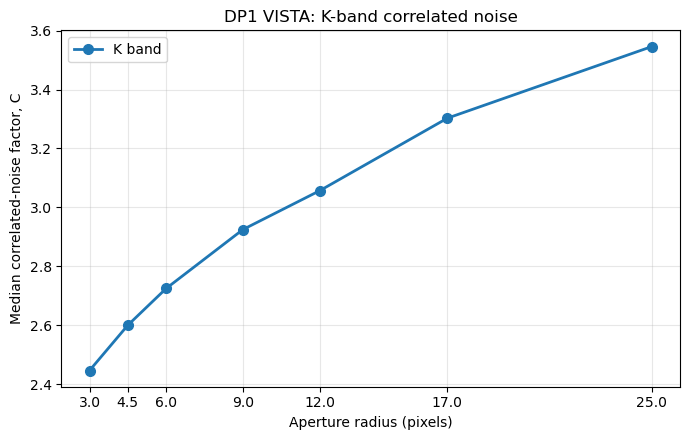

In [13]:

def plot_band_noise(df, band):
    # Apply the same sampling criteria as the final calibration.
    eligible = df[
        np.isfinite(df["C"])
        & (df["N"] >= df["radius"].map(MIN_APERTURES))
    ].copy()

    summary = (
        eligible.groupby("radius")
        .agg(
            median_C=("C", "median"),
            N_patches=("C", "count")
        )
        .reindex(RADII)
    )

    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(
        summary.index,
        summary["median_C"],
        "o-", linewidth=2, markersize=7,
        label=f"{band} band"
    )

    ax.set(
        xlabel="Aperture radius (pixels)",
        ylabel="Median correlated-noise factor, C",
        title=f"DP1 VISTA: {band}-band correlated noise"
    )
    ax.set_xticks(RADII)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    #print(f"{band}-band eligible-patch summary:")
    #print(summary.round(3).to_string())

    return summary


summary_K = plot_band_noise(df_K, "K")


### K-band results

Correlated noise was measured in all 91 K-band patches using seven circular-aperture radii. All patches satisfy the minimum sampling requirements.

The median correction factor increases smoothly from **2.446 at 3 pixels** to **3.546 at 25 pixels**, demonstrating that the formal aperture uncertainties underestimate the measured blank-sky fluctuations.

The increasing correction with aperture radius is consistent with the effect of spatially correlated noise. These results provide a well-sampled K-band reference for the calibration.

Patch-to-patch variations and calibration uncertainties are assessed in the subsequent validation sections before the final correction factors are adopted.


### 12. Measure Z-band correlated noise across every eligible patch
The same seven aperture radii are measured in each Z-band patch that contains both a coadd and a forced catalogue. The results are saved after every patch; this cell can be rerun without repeating completed work. A `NaN` factor indicates fewer than 30 measured blank apertures or an invalid measurement and is not used for calibration.

Z: 42/42 patches in data/DP1_correlated_noise_RSP/patch_noise_Z.csv
        patches  median_C  median_N  min_N
radius                                    
3.0          42     2.666    2000.0    239
4.5          42     2.911    2000.0     85
6.0          42     3.174    2000.0     57
9.0          40     3.509    1500.0      7
12.0         39     3.809    1200.0      3
17.0         37     4.182     700.0      0
25.0         33     4.723     228.0      0


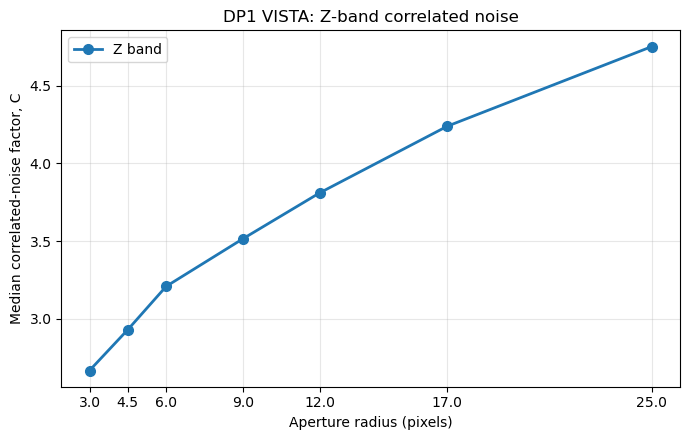

In [14]:
df_Z = process_band("Z")
print(df_Z.groupby("radius").agg(
    patches=("C", "count"), median_C=("C", "median"),
    median_N=("N", "median"), min_N=("N", "min")
).round(3).to_string())


summary_Z = plot_band_noise(df_Z, "Z")


### Z-band results

Correlated noise was measured across 42 Z-band patches using seven circular-aperture radii. The median correction factor increases from **2.666 at 3 pixels** to **4.753 at 25 pixels**, indicating increasing noise correlation with aperture size.

The number of eligible patches decreases from 42 at radius 3 to 29 at radius 25 because fewer clean aperture positions satisfy the minimum sampling requirements. This reduces the spatial coverage of the larger-aperture calibration.

The Z-band correction factors are systematically higher than the corresponding K-band values. Patch-to-patch variation and calibration stability are checked before adopting final factors.

### 13. Measure Y-band correlated noise across every eligible patch
The same seven aperture radii are measured in each Y-band patch that contains both a coadd and a forced catalogue. The results are saved after every patch; this cell can be rerun without repeating completed work. A `NaN` factor indicates fewer than 30 measured blank apertures or an invalid measurement and is not used for calibration.

Y: 89/89 patches in data/DP1_correlated_noise_RSP/patch_noise_Y.csv
        patches  median_C  median_N  min_N
radius                                    
3.0          89     2.757    2000.0   2000
4.5          89     3.146    2000.0   2000
6.0          89     3.576    2000.0   2000
9.0          89     4.218    1500.0   1500
12.0         89     4.894    1200.0    705
17.0         89     5.640     700.0    179
25.0         88     6.659     137.0     19


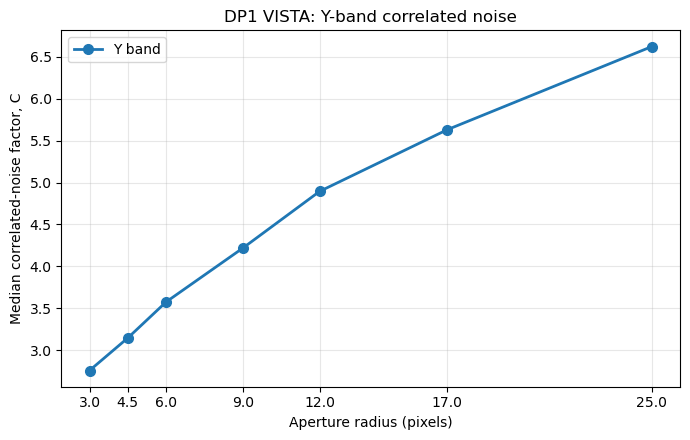

In [15]:
df_Y = process_band("Y")
print(df_Y.groupby("radius").agg(
    patches=("C", "count"), median_C=("C", "median"),
    median_N=("N", "median"), min_N=("N", "min")
).round(3).to_string())

summary_Y = plot_band_noise(df_Y, "Y")

### Y-band results

Correlated noise was measured in 89 Y-band patches. The median correction factor rises from **2.757 at 3 pixels** to **6.623 at 25 pixels**, showing a pronounced increase with aperture radius.

All 89 patches satisfy the sampling requirements through radius 12, while 88 and 74 patches remain eligible at radii 17 and 25, respectively.

The Y-band factors are substantially higher than those in the Z and K bands, particularly for larger apertures. This could reflect stronger spatial noise correlations or additional background fluctuations. Further validation is required to distinguish these effects and assess whether band-wide correction factors are appropriate.


### 14. Measure J-band correlated noise across every eligible patch
The same seven aperture radii are measured in each J-band patch that contains both a coadd and a forced catalogue. The results are saved after every patch; this cell can be rerun without repeating completed work. A `NaN` factor indicates fewer than 30 measured blank apertures or an invalid measurement and is not used for calibration.

J: 91/91 patches in data/DP1_correlated_noise_RSP/patch_noise_J.csv
        patches  median_C  median_N  min_N
radius                                    
3.0          91     2.555    2000.0   2000
4.5          91     2.796    2000.0   2000
6.0          91     3.036    2000.0   2000
9.0          91     3.375    1500.0   1500
12.0         91     3.685    1200.0   1200
17.0         91     4.021     700.0    480
25.0         91     4.805     250.0    106


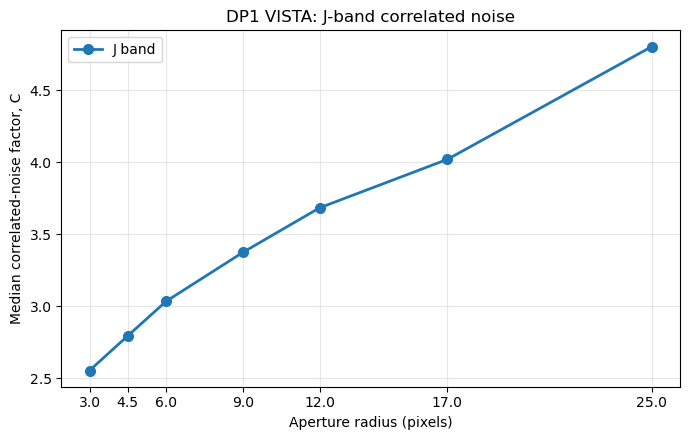

In [16]:
df_J = process_band("J")
print(df_J.groupby("radius").agg(
    patches=("C", "count"), median_C=("C", "median"),
    median_N=("N", "median"), min_N=("N", "min")
).round(3).to_string())

summary_J = plot_band_noise(df_J, "J")

### J-band results

Correlated noise was measured across all 91 J-band patches, with sufficient blank-sky apertures at every radius. The median correction factor increases smoothly from **2.555 at 3 pixels** to **4.805 at 25 pixels**.

The correction factors are higher than those in K band and comparable to Z band at the largest aperture radius. The complete patch coverage provides a well-sampled basis for the J-band calibration.

Patch-to-patch variations and the uncertainty of the median correction factors will be examined in the subsequent validation analysis.


### 15. Measure H-band correlated noise across every eligible patch
The same seven aperture radii are measured in each H-band patch that contains both a coadd and a forced catalogue. The results are saved after every patch; this cell can be rerun without repeating completed work. A `NaN` factor indicates fewer than 30 measured blank apertures or an invalid measurement and is not used for calibration.

H: 91/91 patches in data/DP1_correlated_noise_RSP/patch_noise_H.csv
        patches  median_C  median_N  min_N
radius                                    
3.0          91     2.519    2000.0   2000
4.5          91     2.745    2000.0   2000
6.0          91     2.955    2000.0   2000
9.0          91     3.238    1500.0   1500
12.0         91     3.445    1200.0   1200
17.0         91     3.798     700.0    453
25.0         91     4.169     250.0     98


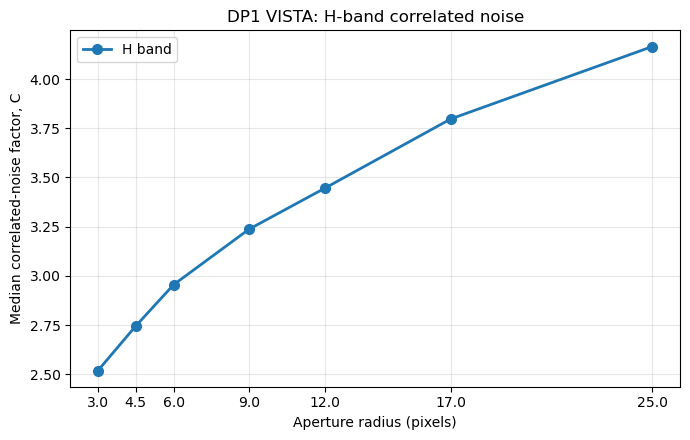

In [17]:
df_H = process_band("H")
print(df_H.groupby("radius").agg(
    patches=("C", "count"), median_C=("C", "median"),
    median_N=("N", "median"), min_N=("N", "min")
).round(3).to_string())

summary_H = plot_band_noise(df_H, "H")

### H-band results

Correlated noise was measured across all 91 H-band patches. The median correction factor increases smoothly from **2.519 at 3 pixels** to approximately **4.17 at 25 pixels**.

The correction factors are consistently higher than those in K band but lower than those in J band. All patches satisfy the sampling requirements through radius 17, while a small number may be excluded at radius 25 due to insufficient clean aperture positions.

The complete measurements provide a strong basis for H-band calibration. Patch-to-patch scatter and uncertainty estimates will be assessed before finalising the correction factors.


### 16. Combine checkpoints and check completeness
Measurements are reloaded from disk instead of relying on variables retained in the notebook kernel. Every eligible band–patch–radius combination is required to have one result, even when the correction itself is `NaN` because sampling was insufficient. This check prevents an incomplete RSP run from being mistaken for a finished calibration.

In [18]:
all_frames = [read_checkpoint(band) for band in BANDS]
df_all = pd.concat(all_frames, ignore_index=True)
for band in BANDS:
    subset = df_all[df_all["band"] == band]
    expected = len(common_by_band[band]) * len(RADII)
    if len(subset) != expected:
        raise RuntimeError(f"{band}: only {len(subset)}/{expected} rows saved")
    actual_keys = set(zip(subset["tract"], subset["patch"], subset["radius"]))
    wanted = {(t, p, r) for t, p in common_by_band[band] for r in RADII}
    if actual_keys != wanted:
        raise RuntimeError(f"{band}: checkpoint patch/radius inventory mismatch")

print("Rows by band:", df_all.groupby("band").size().to_dict())
print("\nMedian correction by band and radius (all non-NaN patches):")
print(df_all.pivot_table(index="radius", columns="band", values="C",
                         aggfunc="median").reindex(columns=BANDS).round(3))
print("\nNumber of patches with at least 30 measured apertures:")
print(df_all.pivot_table(index="radius", columns="band", values="C",
                         aggfunc="count").reindex(columns=BANDS))

Rows by band: {'H': 637, 'J': 637, 'K': 637, 'Y': 623, 'Z': 294}

Median correction by band and radius (all non-NaN patches):
band        Z      Y      J      H      K
radius                                   
3.0     2.666  2.757  2.555  2.519  2.446
4.5     2.911  3.146  2.796  2.745  2.600
6.0     3.174  3.576  3.036  2.955  2.725
9.0     3.509  4.218  3.375  3.238  2.925
12.0    3.809  4.894  3.685  3.445  3.056
17.0    4.182  5.640  4.021  3.798  3.303
25.0    4.723  6.659  4.805  4.169  3.546

Number of patches with at least 30 measured apertures:
band     Z   Y   J   H   K
radius                    
3.0     42  89  91  91  91
4.5     42  89  91  91  91
6.0     42  89  91  91  91
9.0     40  89  91  91  91
12.0    39  89  91  91  91
17.0    37  89  91  91  91
25.0    33  88  91  91  91


### 17. Assess sampling reliability and patch-to-patch scatter
A minimum of 200 independent blank apertures is required for radii 3–17 pixels and 100 for radius 25. The number of accepted patches, median correction and robust patch-to-patch scatter are compared for every band and radius. This distinguishes a statistically useful band-level estimate from a factor dominated by sparsely sampled patches, especially at radius 25.


N_eligible_patches:
band     Z   Y   J   H   K
radius                    
3.0     42  89  91  91  91
4.5     40  89  91  91  91
6.0     38  89  91  91  91
9.0     37  89  91  91  91
12.0    37  89  91  91  91
17.0    31  88  91  91  91
25.0    29  74  91  90  91

C_median:
band        Z      Y      J      H      K
radius                                   
3.0     2.666  2.757  2.555  2.519  2.446
4.5     2.929  3.146  2.796  2.745  2.600
6.0     3.208  3.576  3.036  2.955  2.725
9.0     3.514  4.218  3.375  3.238  2.925
12.0    3.810  4.894  3.685  3.445  3.056
17.0    4.240  5.631  4.021  3.798  3.303
25.0    4.753  6.623  4.805  4.166  3.546

patch_scatter:
band        Z      Y      J      H      K
radius                                   
3.0     0.099  0.115  0.080  0.069  0.067
4.5     0.150  0.167  0.120  0.098  0.090
6.0     0.161  0.275  0.129  0.093  0.103
9.0     0.221  0.417  0.188  0.138  0.146
12.0    0.375  0.538  0.229  0.168  0.135
17.0    0.437  0.692  0.354  0.248  0

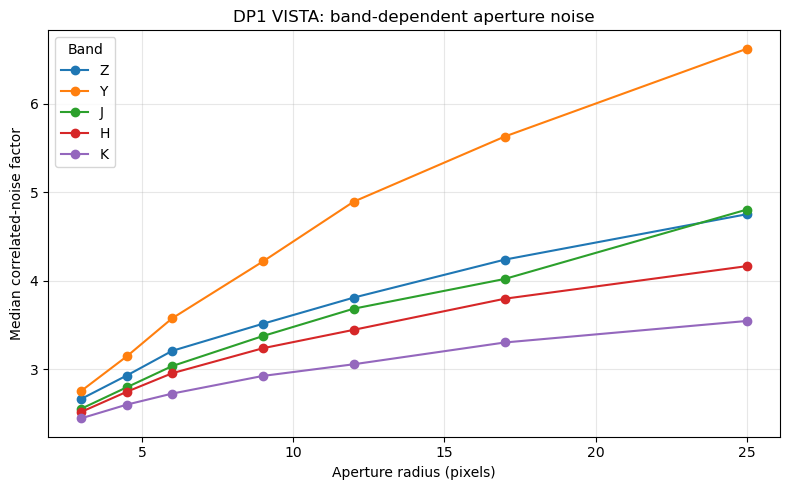

In [19]:
summary_rows = []
for (band, radius), group in df_all.groupby(["band", "radius"]):
    threshold = MIN_APERTURES[float(radius)]
    eligible = group[np.isfinite(group["C"]) & (group["N"] >= threshold)]
    values = eligible["C"].to_numpy()
    summary_rows.append({
        "band": band, "radius": radius, "min_N": threshold,
        "N_all_patches": len(group), "N_eligible_patches": len(eligible),
        "C_median": float(np.median(values)) if len(values) else np.nan,
        "patch_scatter": nmad(values),
        "min_eligible_N": int(eligible["N"].min()) if len(eligible) else 0,
    })
sampling_summary = pd.DataFrame(summary_rows)
for field in ("N_eligible_patches", "C_median", "patch_scatter"):
    print(f"\n{field}:")
    print(sampling_summary.pivot(index="radius", columns="band", values=field)
          .reindex(columns=BANDS).round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for band in BANDS:
    sub = sampling_summary[sampling_summary["band"] == band]
    ax.plot(sub["radius"], sub["C_median"], marker="o", label=band)
ax.set(xlabel="Aperture radius (pixels)", ylabel="Median correlated-noise factor",
       title="DP1 VISTA: band-dependent aperture noise")
ax.grid(alpha=0.3)
ax.legend(title="Band")
plt.tight_layout()
plt.show()

### 18. Inspect unusual patches
Patch-radius measurements are flagged more than three NMADs from their band-level median, provided the robust scatter is nonzero. Outliers are diagnostic flags; they are not automatically discarded, because some differences may reflect genuine background structure or depth variation. The list is retained for targeted checks before using a common band-level correction.

In [20]:
outlier_rows = []
for (band, radius), group in df_all.groupby(["band", "radius"]):
    eligible = group[np.isfinite(group["C"]) &
                     (group["N"] >= MIN_APERTURES[float(radius)])]
    if len(eligible) < 10:
        continue
    median_c = float(eligible["C"].median())
    scatter = nmad(eligible["C"])
    if not np.isfinite(scatter) or scatter == 0:
        continue
    for row in eligible.itertuples():
        deviation = (row.C - median_c) / scatter
        if abs(deviation) > 3:
            outlier_rows.append({
                "band": band, "radius": radius, "tract": row.tract,
                "patch": row.patch, "N": row.N, "C": row.C,
                "deviation_NMAD": deviation,
            })
outliers = pd.DataFrame(outlier_rows, columns=[
    "band", "radius", "tract", "patch", "N", "C", "deviation_NMAD"
])
print("Flagged outlier measurements:", len(outliers))
if not outliers.empty:
    print(outliers.sort_values("deviation_NMAD", key=abs, ascending=False)
          .head(30).round(3).to_string(index=False))

Flagged outlier measurements: 71
band  radius  tract  patch    N     C  deviation_NMAD
   J     4.5   4848     83 2000 3.853           8.837
   J    17.0   4848     83  700 7.026           8.490
   J     9.0   4848     83 1500 4.967           8.479
   J     6.0   4848     83 2000 4.064           7.972
   J    12.0   4848     83 1200 5.492           7.889
   J     3.0   4848     83 2000 3.139           7.310
   H    17.0   4848     83  700 5.482           6.788
   J    25.0   4848     83  250 8.502           6.595
   H     6.0   4848     83 2000 3.529           6.182
   H    12.0   4848     83 1200 4.465           6.060
   H     4.5   4848     83 2000 3.318           5.859
   K    12.0   4848     83 1200 3.790           5.457
   H    12.0   4848     93 1200 4.351           5.384
   H    25.0   4848     83  250 6.169           5.287
   H     9.0   5063      8 1500 3.965           5.268
   H     9.0   4848     83 1500 3.963           5.251
   J    17.0   4848     93  700 5.749           4

In [21]:

# Identify patches repeatedly flagged across bands and radii.
patch_flags = (
    outliers.groupby(["tract", "patch"])
    .agg(
        N_flags=("C", "size"),
        N_bands=("band", "nunique"),
        N_radii=("radius", "nunique")
    )
    .sort_values("N_flags", ascending=False)
)

print("Most frequently flagged patches:")
print(patch_flags.head(15).to_string())

# Compare tract 4848, patch 83 with band-level medians.
patch83 = df_all[
    (df_all["tract"] == 4848)
    & (df_all["patch"] == 83)
].merge(
    sampling_summary[["band", "radius", "C_median"]],
    on=["band", "radius"]
)

patch83["difference_pct"] = (
    100 * (patch83["C"] / patch83["C_median"] - 1)
)

print("\nTract 4848, patch 83 — deviation from band medians (%):")
print(
    patch83.pivot(
        index="radius",
        columns="band",
        values="difference_pct"
    )
    .reindex(columns=BANDS)
    .round(1)
    .to_string()
)

print("\nPatch 83 — clean-sky fraction and aperture counts:")
print(
    patch83[patch83["radius"].isin([6.0, 25.0])]
    [["band", "radius", "N", "N_candidates",
      "good_sky_fraction"]]
    .sort_values(["band", "radius"])
    .round(3)
    .to_string(index=False)
)


Most frequently flagged patches:
             N_flags  N_bands  N_radii
tract patch                           
4848  83          23        4        7
5063  8           14        4        7
4848  93           9        2        5
      73           8        3        6
5063  46           3        1        3
      23           3        2        3
4848  71           1        1        1
4849  75           1        1        1
      76           1        1        1
5063  14           1        1        1
4849  85           1        1        1
5063  26           1        1        1
      24           1        1        1
      27           1        1        1
      43           1        1        1

Tract 4848, patch 83 — deviation from band medians (%):
band     Z     Y     J     H     K
radius                            
3.0    NaN  19.3  22.9  13.1  11.7
4.5    NaN  24.9  37.8  20.8  12.7
6.0    NaN  30.0  33.9  19.4  13.2
9.0    NaN  25.7  47.2  22.4  17.7
12.0   NaN  29.0  49.1  29.6  24.0
17

### 19. Seed stability in representative patches
Radius-6 and radius-25 measurements are repeated using three independently offset aperture grids in the K- and Y-band reference patches. A large spread in the resulting factors would reveal sensitivity to the selected blank-sky positions, especially at radius 25. This check is independent of the final band-level bootstrap and does not modify the saved measurements.

In [22]:
seed_rows = []
for band in ("K", "Y"):
    patches = common_by_band[band]
    key = (REFERENCE_PATCH if band == "K"
           else patches[len(patches) // 2])
    exp = butler.get(coadd_refs[band][key])
    _, dist = valid_sky_and_distance(exp)
    for radius in (6.0, 25.0):
        for offset in (0, 1, 2):
            pts, n_candidates = sample_positions(
                dist, radius, TARGETS[radius],
                patch_seed(band, *key, radius) + offset * 104729
            )
            if len(pts) >= 30:
                f, e = aperture_arrays(exp, pts, radius)
                c = noise_factor(f, e)
            else:
                c = np.nan
            seed_rows.append({"band": band, "tract": key[0], "patch": key[1],
                              "radius": radius, "offset": offset,
                              "N": len(pts), "C": c})
    del exp, dist
seed_stability = pd.DataFrame(seed_rows)
print(seed_stability.round(3).to_string(index=False))
print("\nSeed-to-seed factor range:")
print(seed_stability.groupby(["band", "radius"])["C"]
      .agg(["count", "min", "median", "max"]).round(3).to_string())

band  tract  patch  radius  offset    N      C
   K   5063     22     6.0       0 2000  2.993
   K   5063     22     6.0       1 2000  2.819
   K   5063     22     6.0       2 2000  2.812
   K   5063     22    25.0       0  250  4.308
   K   5063     22    25.0       1  250  3.988
   K   5063     22    25.0       2  250  3.577
   Y   5063     10     6.0       0 2000  3.910
   Y   5063     10     6.0       1 2000  3.886
   Y   5063     10     6.0       2 2000  3.810
   Y   5063     10    25.0       0  149  9.013
   Y   5063     10    25.0       1  162  9.490
   Y   5063     10    25.0       2  139 10.271

Seed-to-seed factor range:
             count    min  median     max
band radius                              
K    6.0         3  2.812   2.819   2.993
     25.0        3  3.577   3.988   4.308
Y    6.0         3  3.810   3.886   3.910
     25.0        3  9.013   9.490  10.271


### Result: Spatial variation and sampling stability

The correlated-noise factors exhibit measurable patch-to-patch variations, which become larger at increasing aperture radius. Several patches show systematically elevated factors across multiple bands, particularly tract 4848, patch 83. These deviations cannot be explained solely by insufficient aperture samples and may reflect spatial differences in coadd noise properties or residual background structure.

Repeating the measurements with different sampling seeds produces relatively stable factors at radius 6, while larger variations occur at radius 25, where fewer independent blank-sky apertures are available.

These results highlight two sources of variability: spatial differences between patches and sensitivity to aperture placement within individual patches. Both should be considered when evaluating the final calibration. Outlying patches are retained pending further validation.


### 20. Derive final band-dependent correction factors
For each band and radius, the median factor is calculated across eligible patches. Bootstrap resampling estimates the precision of the median; both the 95% confidence interval and the robust patch-to-patch NMAD are retained. The calibration is rejected if fewer than 10 patches qualify for any of the 35 band–radius combinations.

In [23]:
rng_boot = np.random.default_rng(SEED + 99)
N_BOOT = 2000
MIN_PATCHES = 10
calibration_rows = []
for band in BANDS:
    for radius in RADII:
        group = df_all[(df_all["band"] == band) &
                       (df_all["radius"] == radius)]
        eligible = group[np.isfinite(group["C"]) &
                         (group["N"] >= MIN_APERTURES[radius])]
        values = eligible["C"].to_numpy(dtype=float)
        if len(values) < MIN_PATCHES:
            raise RuntimeError(
                f"Insufficient calibrated patches for {band}, r={radius}: "
                f"{len(values)} < {MIN_PATCHES}. Review the sampling threshold."
            )
        bootstrap = np.median(
            rng_boot.choice(values, size=(N_BOOT, len(values)), replace=True),
            axis=1
        )
        lo, hi = np.percentile(bootstrap, (2.5, 97.5))
        calibration_rows.append({
            "band": band, "radius": radius,
            "N_patches": len(values),
            "min_N_apertures": MIN_APERTURES[radius],
            "C_median": float(np.median(values)),
            "C_low95": float(lo), "C_high95": float(hi),
            "patch_scatter": nmad(values),
        })

calibration = pd.DataFrame(calibration_rows)
calibration["CI_halfwidth_pct"] = (
    100 * (calibration["C_high95"] - calibration["C_low95"])
    / (2 * calibration["C_median"])
)
print("Median factors:")
print(calibration.pivot(index="radius", columns="band", values="C_median")
      .reindex(columns=BANDS).round(3).to_string())
print("\n95% CI half-width (%):")
print(calibration.pivot(index="radius", columns="band", values="CI_halfwidth_pct")
      .reindex(columns=BANDS).round(2).to_string())

Median factors:
band        Z      Y      J      H      K
radius                                   
3.0     2.666  2.757  2.555  2.519  2.446
4.5     2.929  3.146  2.796  2.745  2.600
6.0     3.208  3.576  3.036  2.955  2.725
9.0     3.514  4.218  3.375  3.238  2.925
12.0    3.810  4.894  3.685  3.445  3.056
17.0    4.240  5.631  4.021  3.798  3.303
25.0    4.753  6.623  4.805  4.166  3.546

95% CI half-width (%):
band        Z     Y     J     H     K
radius                               
3.0      1.63  0.92  1.04  0.87  0.75
4.5      2.19  1.59  1.01  0.64  1.02
6.0      2.23  1.38  1.03  0.84  0.99
9.0      2.60  3.19  1.70  1.22  1.31
12.0     4.83  3.64  1.46  1.32  1.38
17.0     4.66  3.41  2.46  1.91  1.35
25.0    10.06  6.25  3.38  2.37  2.85


### Result: Band-level calibration and statistical uncertainty

Median correlated-noise factors were derived from eligible patches in each band and aperture radius. The factors increase systematically with aperture size, with the strongest corrections occurring in Y band.

Bootstrap resampling of patches gives relatively narrow 95% confidence intervals for the median factors at small radii, with half-widths generally below 2.3% for radii 3–6 pixels. At radius 25, the uncertainties increase, particularly in Z (10.1%) and Y (6.3%).

These confidence intervals quantify the statistical precision of the band-level medians but do not represent the full spatial variation between patches. The calibration factors remain provisional pending tests of tract dependence and catalogue uncertainty consistency.


### 21. Test sensitivity to individual tracts
Each median is recomputed while leaving out one tract at a time. This tests whether a small number of tracts dominate the result despite the number of qualifying patches. The bootstrap intervals above describe sampling of patches and do not automatically capture all spatial systematics.

In [24]:
tract_rows = []
for band in BANDS:
    for radius in RADII:
        group = df_all[(df_all["band"] == band) &
                       (df_all["radius"] == radius) &
                       np.isfinite(df_all["C"]) &
                       (df_all["N"] >= MIN_APERTURES[radius])]
        full = float(group["C"].median())
        for omit_tract in sorted(group["tract"].unique()):
            other = group[group["tract"] != omit_tract]
            tract_rows.append({
                "band": band, "radius": radius, "omitted_tract": int(omit_tract),
                "remaining_patches": len(other),
                "change_pct": 100 * (float(other["C"].median()) / full - 1)
                if len(other) >= MIN_PATCHES and full > 0 else np.nan,
            })
tract_sensitivity = pd.DataFrame(tract_rows)
print("Largest absolute change in median after omitting one tract (%):")
print(tract_sensitivity.assign(abs_change=lambda d: d["change_pct"].abs())
      .groupby(["radius", "band"])["abs_change"].max()
      .unstack("band").reindex(columns=BANDS).round(2).to_string())

Largest absolute change in median after omitting one tract (%):
band       Z     Y     J     H     K
radius                              
3.0     1.04  0.75  0.08  0.34  0.28
4.5     0.90  0.38  0.49  0.18  0.08
6.0     0.41  0.86  0.67  0.87  1.12
9.0     0.00  3.26  0.76  0.75  0.89
12.0    0.00  4.40  1.11  0.52  0.69
17.0    0.93  2.70  3.18  2.22  0.19
25.0    0.00  1.41  1.84  0.07  0.73


### Tract-dependence results

Leave-one-tract-out tests show that the band-level correction factors are generally stable, with changes below 4.5% in the evaluable comparisons.

The greatest sensitivity occurs in Y band at radius 12 pixels (4.4%) and J band at radius 17 pixels (3.2%).

The Z-band results require additional caution. At radii 17 and 25 pixels, most eligible patches belong to tract 5063, leaving only two patches when this tract is excluded. Consequently, the robustness of the Z-band calibration across independent tracts cannot be established at these radii.

The results support the use of representative band-level corrections, while spatial variations and uneven tract coverage remain important calibration limitations.


### 22. Confirm the catalogue uncertainty fields
The seven actual `base_CircularApertureFlux_*_instFluxErr` fields are verified in one forced catalogue per band. The later CSD3 processing will multiply *only* positive finite errors in these seven fields, preserving all fluxes, flags, unrelated uncertainties, schema and metadata. This notebook does not change any catalogue.

In [25]:
error_fields = {
    r: f"base_CircularApertureFlux_{r:.1f}".replace(".", "_") + "_instFluxErr"
    for r in RADII
}
for band in BANDS:
    key = common_by_band[band][len(common_by_band[band]) // 2]
    cat = butler.get(forced_refs[band][key])
    missing = [field for field in error_fields.values()
               if field not in cat.schema.getNames()]
    print(f"{band}: tract={key[0]}, patch={key[1]}, "
          f"sources={len(cat)}, fields={len(cat.schema.getNames())}, "
          f"missing aperture-error fields={missing}")
    if missing:
        raise RuntimeError(f"Missing required aperture error fields for {band}")
    del cat
print("\nFields to correct on CSD3:")
for radius, name in error_fields.items():
    print(f"  r={radius:4.1f}: {name}")

Z: tract=5063, patch=25, sources=20019, fields=367, missing aperture-error fields=[]
Y: tract=5063, patch=10, sources=12368, fields=367, missing aperture-error fields=[]
J: tract=5063, patch=8, sources=2824, fields=367, missing aperture-error fields=[]
H: tract=5063, patch=8, sources=2824, fields=367, missing aperture-error fields=[]
K: tract=5063, patch=8, sources=2824, fields=367, missing aperture-error fields=[]

Fields to correct on CSD3:
  r= 3.0: base_CircularApertureFlux_3_0_instFluxErr
  r= 4.5: base_CircularApertureFlux_4_5_instFluxErr
  r= 6.0: base_CircularApertureFlux_6_0_instFluxErr
  r= 9.0: base_CircularApertureFlux_9_0_instFluxErr
  r=12.0: base_CircularApertureFlux_12_0_instFluxErr
  r=17.0: base_CircularApertureFlux_17_0_instFluxErr
  r=25.0: base_CircularApertureFlux_25_0_instFluxErr


### Result: Catalogue field verification

The seven circular-aperture flux uncertainty fields were verified in representative `deepCoadd_forced_src` catalogues from all five VISTA bands. All required fields are present, with consistent catalogue schema sizes.

The subsequent catalogue correction will target only these seven aperture uncertainty fields, preserving the original flux measurements, quality flags, unrelated uncertainties and catalogue metadata.

No catalogue modifications are performed during the RSP calibration analysis.


### 23. Check source-brightness dependence of formal aperture errors
The K-band radius-6 catalogue error is compared with the local coadd variance for sources spanning a broad range of brightness. The quantity below is a diagnostic ratio, not a clean decomposition of photon noise and sky noise: LSST aperture weighting differs slightly from fractional-circle weights, and crowded-source backgrounds can be biased. A strong increase among the brightest sources would flag where a simple correction of the *entire* formal uncertainty needs particular validation on CSD3.

In [26]:
key = REFERENCE_PATCH
cat = butler.get(forced_refs["K"][key])
exp = butler.get(coadd_refs["K"][key])
prefix = "base_CircularApertureFlux_6_0"
f = np.asarray(cat[prefix + "_instFlux"], dtype=float)
e = np.asarray(cat[prefix + "_instFluxErr"], dtype=float)
x = np.asarray(cat["base_SdssCentroid_x"], dtype=float) - exp.getXY0().getX()
y = np.asarray(cat["base_SdssCentroid_y"], dtype=float) - exp.getXY0().getY()
flag_field = prefix + "_flag"
flag = np.asarray(cat[flag_field], dtype=bool) if flag_field in cat.schema.getNames() else np.zeros(len(cat), dtype=bool)
var = exp.variance.array
ny, nx = var.shape
valid = (~flag & np.isfinite(f) & (f > 0) & np.isfinite(e) & (e > 0)
         & np.isfinite(x) & np.isfinite(y)
         & (x >= 21) & (y >= 21) & (x < nx - 21) & (y < ny - 21))
indices = np.where(valid)[0]
if len(indices) < 30:
    print("Fewer than 30 usable K-band sources; brightness test inconclusive")
    brightness_check = pd.DataFrame()
else:
    # Uniform quantile sampling includes faint and very bright sources.
    sorted_indices = indices[np.argsort(f[indices])]
    selected = sorted_indices[np.unique(np.linspace(
        0, len(sorted_indices) - 1, min(1500, len(sorted_indices))
    ).astype(int))]
    yy, xx = np.mgrid[-20:21, -20:21]
    annulus = (np.hypot(xx, yy) >= 12) & (np.hypot(xx, yy) <= 20)
    w2_sum = float(np.sum(WEIGHTS[6.0] ** 2))
    measurements = []
    for i in selected:
        cx, cy = int(round(x[i])), int(round(y[i]))
        region = var[cy-20:cy+21, cx-20:cx+21]
        local = region[annulus]
        local = local[np.isfinite(local) & (local > 0)]
        if len(local) < 300:
            continue
        sky_variance = float(np.median(local))
        measurements.append({
            "flux": f[i], "err2_over_sky_prediction":
                float(e[i]**2 / (sky_variance * w2_sum))
        })
    brightness_check = pd.DataFrame(measurements)
    if len(brightness_check) >= 30:
        brightness_check["brightness_group"] = pd.qcut(
            brightness_check["flux"], q=[0, .5, .9, .99, 1],
            labels=["Faint half", "50–90%", "90–99%", "Brightest 1%"],
            duplicates="drop"
        )
        print(brightness_check.groupby("brightness_group", observed=True)
              .agg(N=("flux", "size"), median_flux=("flux", "median"),
                   median_ratio=("err2_over_sky_prediction", "median"))
              .round(3).to_string())
    else:
        print("Too few valid local-variance measurements for a brightness comparison")
del cat, exp

                    N  median_flux  median_ratio
brightness_group                                
Faint half        750      247.151         1.030
50–90%            600     1249.113         1.030
90–99%            135    13996.051         1.031
Brightest 1%       15   373787.688         1.047


### Result: Source-brightness dependence

The relationship between catalogue aperture uncertainties and local coadd variance was examined for 1,500 K-band sources at radius 6 pixels. The median ratio of squared catalogue uncertainty to the local variance prediction remains approximately 1.03 across the faint and intermediate brightness groups, increasing slightly to 1.047 for the brightest 1%.

No strong brightness dependence is evident in this diagnostic. However, the test is limited to one patch and aperture radius and does not independently separate source photon noise from background noise. The applicability of the multiplicative correction to bright sources therefore requires further validation.


### 24. Independent validation using held-out patches

The band-level correlated-noise calibration is tested on representative and high-noise patches in all five VISTA bands.
For each band, two validation patches are excluded from the calibration, and the median correction factors are recalculated using the remaining eligible patches. New blank-sky aperture measurements are then performed in the excluded patches using independent sampling seeds.
The ratio between the measured blank-sky noise and the predicted corrected uncertainty should be close to unity when the band-level calibration adequately represents the local noise.
The analysis focuses on radii 3–17 pixels. Radius 25 is retained as a supplementary diagnostic because of its greater sampling uncertainty and spatial variability.
This patch-level hold-out test evaluates the transferability of the calibration to excluded patches and identifies limitations associated with spatially varying noise.


Z: typical patch (5063, 23) validated
Z: high-noise patch (5063, 14) validated
Y: typical patch (4849, 79) validated
Y: high-noise patch (4848, 83) validated
J: typical patch (4849, 97) validated
J: high-noise patch (4848, 83) validated
H: typical patch (5063, 5) validated
H: high-noise patch (4848, 83) validated
K: typical patch (4848, 71) validated
K: high-noise patch (4848, 83) validated

TYPICAL: held-out C / correction from other patches
band        Z      Y      J      H      K
radius                                   
3.0     1.010  1.085  0.906  0.979  1.048
4.5     1.104  0.992  0.980  1.037  1.051
6.0     1.026  0.968  0.988  1.140  0.985
9.0     1.024  0.954  1.017  1.030  0.934
12.0    1.025  0.916  1.014  1.041  1.080
17.0    1.058  1.128  1.007  0.921  1.211
25.0      NaN  1.120  0.837  1.026  1.020

HIGH-NOISE: held-out C / correction from other patches
band        Z      Y      J      H      K
radius                                   
3.0     1.062  1.217  1.179  1.053 

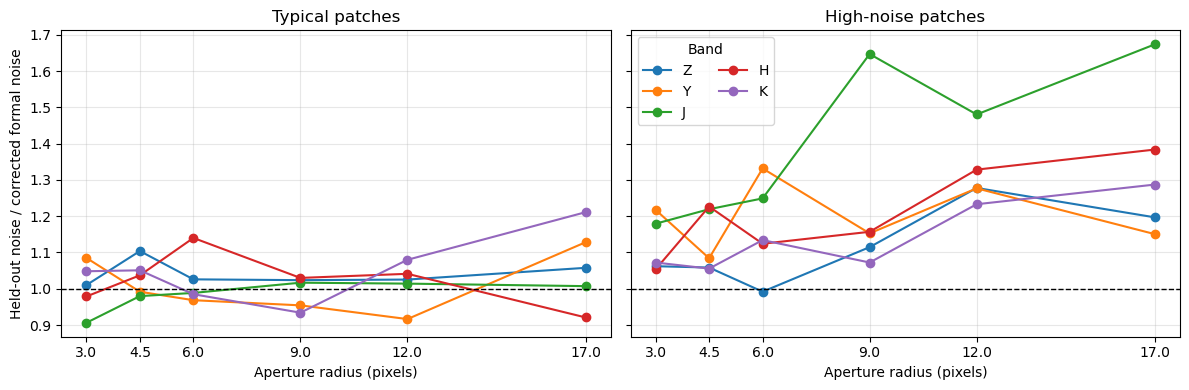

Saved: data/DP1_correlated_noise_RSP/DP1_aperture_noise_holdout_validation.csv


In [27]:

# Spatial hold-out: the validation patches do not contribute to the
# band-level correction against which they are tested.
VALIDATION_PATCHES = {
    "Z": {"typical": (5063, 23), "high-noise": (5063, 14)},
    "Y": {"typical": (4849, 79), "high-noise": (4848, 83)},
    "J": {"typical": (4849, 97), "high-noise": (4848, 83)},
    "H": {"typical": (5063, 5),  "high-noise": (4848, 83)},
    "K": {"typical": (4848, 71), "high-noise": (4848, 83)},
}
TEST_TARGETS = {3.0: 600, 4.5: 600, 6.0: 600,
                9.0: 500, 12.0: 400, 17.0: 300, 25.0: 150}

# Recalculate median factors excluding both validation patches.
predicted = {}

for band, cases in VALIDATION_PATCHES.items():
    held_out = set(cases.values())

    for radius in RADII:
        sub = df_all[
            (df_all.band == band)
            & (df_all.radius == radius)
            & (df_all.N >= MIN_APERTURES[radius])
            & np.isfinite(df_all.C)
        ]

        keep = [
            (int(t), int(p)) not in held_out
            for t, p in zip(sub.tract, sub.patch)
        ]
        remaining = sub.loc[keep, "C"]

        assert len(remaining) >= 10, (band, radius)
        predicted[(band, radius)] = (
            float(remaining.median()), len(remaining)
        )

# Measure new blank-sky apertures in the excluded patches.
validation_rows = []

for band, cases in VALIDATION_PATCHES.items():
    for case, (tract, patch) in cases.items():
        exp = butler.get(coadd_refs[band][(tract, patch)])
        _, distance = valid_sky_and_distance(exp)

        for radius in RADII:
            c_predict, n_training_patches = predicted[(band, radius)]

            seed = patch_seed(band, tract, patch, radius) + 1000003
            positions, _ = sample_positions(
                distance, radius, TEST_TARGETS[radius], seed
            )

            count = len(positions)
            c_test = lo = hi = np.nan

            if count >= 30:
                flux, formal = aperture_arrays(
                    exp, positions, radius
                )
                c_test = noise_factor(flux, formal)

                # Bootstrap uncertainty of the validation measurement.
                normalized = (flux - np.median(flux)) / formal
                rng = np.random.default_rng(seed + 1200007)

                replicates = [
                    nmad(rng.choice(normalized, count, replace=True))
                    for _ in range(250)
                ]
                lo, hi = np.percentile(replicates, [2.5, 97.5])

            ok = count >= MIN_APERTURES[radius]

            validation_rows.append({
                "band": band,
                "case": case,
                "tract": tract,
                "patch": patch,
                "radius": radius,
                "N_test": count,
                "eligible": ok,
                "N_training_patches": n_training_patches,
                "C_predict": c_predict,
                "C_test": c_test,
                "ratio": c_test / c_predict if ok else np.nan,
                "ratio_lo95": lo / c_predict if ok else np.nan,
                "ratio_hi95": hi / c_predict if ok else np.nan,
            })

        print(
            f"{band}: {case} patch {(tract, patch)} validated",
            flush=True
        )
        del exp, distance
        gc.collect()

validation = pd.DataFrame(validation_rows)

path = OUTDIR / "DP1_aperture_noise_holdout_validation.csv"
validation.to_csv(path, index=False)

# Compare measured noise with predicted corrected uncertainty.
for case in ("typical", "high-noise"):
    subset = validation[validation.case == case]

    print(
        f"\n{case.upper()}: "
        "held-out C / correction from other patches"
    )
    print(
        subset.pivot(
            index="radius", columns="band", values="ratio"
        )
        .reindex(index=RADII, columns=BANDS)
        .round(3)
        .to_string()
    )

print(
    "\nEligible comparisons:",
    int(validation.eligible.sum()), "of", len(validation)
)
print("\nInsufficient aperture counts (if any):")
print(
    validation.loc[
        ~validation.eligible,
        ["band", "case", "radius", "N_test"]
    ].to_string(index=False)
)

# Main scientific figure: radii 3–17 pixels.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, case in zip(axes, ("typical", "high-noise")):
    for band in BANDS:
        subset = validation[
            (validation.band == band)
            & (validation.case == case)
            & (validation.radius <= 17)
        ]
        ax.plot(
            subset.radius, subset.ratio, "o-", label=band
        )

    ax.axhline(1, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=case.capitalize() + " patches",
        xlabel="Aperture radius (pixels)"
    )
    ax.set_xticks(RADII[:-1])
    ax.grid(alpha=0.3)

axes[0].set_ylabel(
    "Held-out noise / corrected formal noise"
)
axes[1].legend(title="Band", ncol=2)

plt.tight_layout()
plt.show()

print("Saved:", path)


### Hold-out validation results

- The band-level calibration was evaluated using five representative and five high-noise patches excluded from the corresponding calibration estimates. Of the 70 validation measurements, 69 satisfied the minimum aperture-sampling requirements.
- For radii 3–17 pixels, the representative patches show good agreement between measured blank-sky fluctuations and predicted corrected uncertainties. The median measured-to-predicted noise ratio is **1.020**, with 26 of 30 comparisons agreeing within 10%.
- The high-noise patches exhibit systematically larger residuals, with a median ratio of **1.188**. The strongest deviation occurs in J band at radius 17 pixels (ratio 1.674), demonstrating that a single band-level factor cannot fully capture spatial variations in the noise properties.
- At radius 25 pixels, the validation is less reliable because of reduced sampling and larger spatial variations. These corrections are therefore retained with additional caution.
- Overall, the results support the use of band-level median factors as an empirical, first-order correction for circular-aperture background noise. The method provides a reproducible calibration that performs well in the selected representative regions, while local deviations remain an important limitation. The factors describe empirical aperture-noise fluctuations, potentially including both correlated pixel noise and residual background structure, rather than isolating pixel correlations alone.


### 25. Export and verify the calibration products
All 35 factors are checked for finite positive values before exporting the complete per-patch results, the 35 band–radius factors, the tract-sensitivity table and the provenance configuration. The band–radius calibration CSV is the input for the separate CSD3 correction script; the remaining exports document the measurements, diagnostics and validation. The factors represent blank-sky noise; applying one multiplier to a total catalogue error can overcorrect the source-dominated component of very bright objects, so this limitation must be checked during the catalogue validation on CSD3.

In [28]:
expected = {(band, radius) for band in BANDS for radius in RADII}
actual = set(zip(calibration["band"], calibration["radius"]))
if actual != expected or len(calibration) != 35:
    raise RuntimeError("Calibration does not contain exactly 35 unique factors")
if not (np.isfinite(calibration["C_median"]).all() and
        (calibration["C_median"] > 0).all()):
    raise RuntimeError("Calibration contains invalid correction factors")
if (calibration["C_median"] < 1).any():
    warnings.warn("At least one factor is < 1: inspect before applying corrections")

exports = {
    "DP1_aperture_noise_by_patch.csv": df_all.sort_values(
        ["band", "tract", "patch", "radius"]),
    "DP1_aperture_noise_calibration.csv": calibration.sort_values(
        ["band", "radius"]),
    "DP1_aperture_noise_tract_sensitivity.csv": tract_sensitivity.sort_values(
        ["band", "radius", "omitted_tract"]),
    "DP1_aperture_noise_outliers.csv": outliers.sort_values(
        ["band", "radius"]),
    "DP1_aperture_noise_holdout_validation.csv": validation.sort_values(
        ["band", "case", "radius"]),
}
for filename, frame in exports.items():
    destination = OUTDIR / filename
    tmp = OUTDIR / (filename + ".tmp")
    frame.to_csv(tmp, index=False)
    tmp.replace(destination)
    print(f"{destination}: {len(frame)} rows")

check = pd.read_csv(OUTDIR / "DP1_aperture_noise_calibration.csv")
assert len(check) == 35
assert set(zip(check["band"], check["radius"])) == expected
print("\nVerified the exported calibration table.")
print("Butler remains read-only; no corrected catalogue has been written.")

data/DP1_correlated_noise_RSP/DP1_aperture_noise_by_patch.csv: 2828 rows
data/DP1_correlated_noise_RSP/DP1_aperture_noise_calibration.csv: 35 rows
data/DP1_correlated_noise_RSP/DP1_aperture_noise_tract_sensitivity.csv: 164 rows
data/DP1_correlated_noise_RSP/DP1_aperture_noise_outliers.csv: 71 rows
data/DP1_correlated_noise_RSP/DP1_aperture_noise_holdout_validation.csv: 70 rows

Verified the exported calibration table.
Butler remains read-only; no corrected catalogue has been written.


### 26. Method transfer to DP2
The DP1 results and checkpoint files **must not** be reused as DP2 calibrations. To apply the same *method* to DP2, first confirm the DP2 Butler repository and collections, coadd/cell-coadd dataset type, sky map, band mapping, pixel scale, mask-plane availability, aperture definitions, and catalogue uncertainty fields. In particular, the cell-coadd processing model may differ from the DP1 coadds, and the presence or meaning of mask planes (including `SENSOR_EDGE` and `INEXACT_PSF`) must be checked anew. The input coadds should be inspected for variance normalisation before running blank apertures.

The reproducible sequence is: coadd/field inventory → mask and variance diagnostics → native-aperture comparison → per-patch blank apertures → sampling and spatial checks → band-level median/bootstrap → independent held-out validation → export. A separate output directory and configuration manifest are required for each new data release. The DP1 factors are not assumed to apply to DP2.

The DP1 mask list is kept unchanged for reproducibility; it does not include `INEXACT_PSF`, although this plane was present in the reference exposure. Any different mask policy for DP2 must be justified and must trigger a new calibration rather than reuse of the DP1 factors.